# Latence cœur → peau : cross-corrélation et autoencodeur (v6)

**Question de l'équipe :** la peau (conductance, GSR) réagit plus lentement que le cœur. De combien de secondes ? Et ce délai change-t-il entre les vidéos à activation haute et basse ?

**Ce que fait ce notebook :** il mesure le délai cœur → peau **dans le temps**, à l'intérieur de chaque vidéo, avec trois méthodes indépendantes :

| Méthode | Principe | Délai estimé |
| --- | --- | --- |
| **Cross-corrélation** | l'outil de Hugo (`latence()`, validé à l'étape 1 sur respiration → cœur) | le décalage où cœur et peau se ressemblent le plus |
| **Régression linéaire** | prédire 8 s de peau à partir de 8 s de cœur, pour chaque décalage de la peau | le décalage où la prédiction est la meilleure |
| **Autoencodeur multimodal** | le même autoencodeur cœur–peau que dans mes notebooks précédents, appliqué à des morceaux de signal ; sa règle de **traduction** cœur → peau est mesurée pour chaque décalage | le décalage où la traduction est la meilleure |

La régression et l'autoencodeur sont évalués sur des **participants jamais vus** (validation croisée par groupes de participants). Si les trois méthodes trouvent le même délai, le résultat est solide.

**Contrôles, dans l'esprit de l'étape 1 :**

1. **Délai connu** : sur un signal synthétique où la peau suit le cœur avec un délai fixé, chaque méthode doit le retrouver.
2. **Paires mélangées** : le cœur d'une vidéo associé à la peau d'une **autre** vidéo du même participant. Un vrai lien doit faire mieux que ces paires, sinon il n'y a rien à mesurer.

**Convention (la même que Hugo) :** délai **> 0 = la peau est en retard sur le cœur**.

**Avant de lancer :** même installation que la v3 (`torch` compris). Pas de GPU. Pour être cohérent avec Hugo, qui travaille sur les fichiers `CURATED`, mettre `VERSION = "CURATED"` si tu les as téléchargés ; par défaut le notebook utilise `PREPROCESSED`, où l'ECG et la peau n'ont reçu qu'un filtre secteur à 50 Hz.

In [1]:
import json
import sys
from itertools import permutations
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyedflib
import torch
from IPython.display import display
from scipy.signal import butter, correlate, correlation_lags, find_peaks, sosfiltfilt
from scipy.stats import spearmanr, wilcoxon
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from torch import nn

cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Lancer le noyau depuis la racine du repo ou depuis starting_notebooks/.")
if str(ROOT / "starting_notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import uV_to_uS

mne.set_log_level("ERROR")
torch.set_num_threads(1)

## 1 · Réglages et participants

In [2]:
DATA_ROOT = ROOT / "sample"
VERSION = "PREPROCESSED"   # "CURATED" pour travailler comme Hugo (signaux bruts)
BDF_ROOT = DATA_ROOT / VERSION
TRIAL_S = 10.0          # fenêtre analysée après le début de la vidéo (s)
BASELINE_S = 2.0        # référence avant la vidéo (s)
MIN_TRIALS = 10         # bons essais minimum par participant
FS_GRID = 4.0           # Hz : grille commune du cœur et de la peau (pas de 0,25 s)
BAND_HZ = (0.02, 0.5)   # filtre à phase nulle : retire la dérive lente, garde les réactions
MIN_VIDEO_S = 8         # vidéos plus courtes ignorées (s)
POST_S = 8              # secondes gardées après la fin de la vidéo (la peau réagit encore)
MAX_VIDEO_S = 120       # fenêtre plafonnée (s)
LAG_MAX_S = 6           # cross-corrélation : délais testés de −6 à +6 s
SEG_S, SEG_STEP_S = 8, 2            # morceaux de 8 s, tous les 2 s
TAUS = np.arange(-2, 6.01, 0.5)      # décalages de la peau testés pour la régression et l'autoencodeur (s)
N_FOLDS = 5             # validation croisée par groupes de participants
PARTICIPANT_IDS = None  # None : tous les participants téléchargés
USE_CACHE = True        # garde les résumés calculés dans sample/features_cache/ (relances bien plus rapides)
DOWNLOAD_N = 0          # >0 : télécharge ce nombre de participants en plus (via download_participants.py)
DOWNLOAD_SEED = 42

labels_path = DATA_ROOT / "labels_train.csv"
if not labels_path.is_file():
    raise FileNotFoundError(f"Télécharger labels_train.csv dans {DATA_ROOT}.")
labels = pd.read_csv(labels_path, na_values=["TESTSUBJECT"], usecols=[
    "cohort", "participant_id", "day", "start_marker", "rating_arousal"])
labels["participant_id"] = labels["participant_id"].astype(str).str.strip()
labels["day"] = pd.to_numeric(labels["day"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
labels["start_marker"] = pd.to_numeric(labels["start_marker"], errors="coerce")
labels["rating_arousal"] = pd.to_numeric(labels["rating_arousal"], errors="coerce")
labels = labels.dropna(subset=["day", "start_marker"])
labels[["day", "start_marker"]] = labels[["day", "start_marker"]].astype(int)
keys = ["participant_id", "day", "start_marker"]
if labels.duplicated(keys).any():
    raise ValueError("Marqueurs ambigus dans labels_train.csv.")


def downloaded_ids():
    found = BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf")
    return {path.parent.name for path in found}


if DOWNLOAD_N > 0:
    # Même téléchargement que download_participants.py (à la racine du repo), fichier par fichier, peu de mémoire.
    import subprocess
    script = ROOT / "download_participants.py"
    if not script.is_file():
        raise FileNotFoundError(f"Mettre download_participants.py dans {ROOT}.")
    subprocess.run([sys.executable, str(script), "--n", str(DOWNLOAD_N), "--seed", str(DOWNLOAD_SEED),
                    "--data-root", str(DATA_ROOT)], check=True, cwd=ROOT)

available_bdfs = sorted(BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf"))
if PARTICIPANT_IDS is not None:
    by_id = {bdf.parent.name: bdf for bdf in available_bdfs}
    missing = sorted(set(PARTICIPANT_IDS) - set(by_id))
    if missing:
        raise FileNotFoundError(f"Fichiers manquants : {missing}")
    available_bdfs = [by_id[p] for p in PARTICIPANT_IDS]
bdfs = available_bdfs
if not bdfs:
    raise FileNotFoundError(f"Aucun fichier emotion-video du jour 1 dans {BDF_ROOT} (VERSION = {VERSION}).")

marker_key = pd.read_csv(ROOT / "starting_notebooks" / "markers.csv")
video_key = marker_key.loc[marker_key["Start Marker"] >= 10100].set_index("Start Marker")
end_marker = video_key["End Marker"].to_dict()

selected = [bdf.parent.name for bdf in bdfs]
cohorts = labels.loc[labels.participant_id.isin(selected)].groupby("participant_id").cohort.first()
print(f"{len(bdfs)} enregistrements sélectionnés : {', '.join(selected)}")
print("Participants par cohorte :", cohorts.value_counts().sort_index().to_dict())

26 enregistrements sélectionnés : P001, P017, P020, P026, P086, P090, P097, P124, P126, P128, P129, P131, P137, P138, P174, P186, P187, P189, P194, P201, P217, P219, P308, P310, P367, P459
Participants par cohorte : {1: 14, 2: 8, 3: 2, 4: 1, 5: 1}


## 2 · Les fonctions de Hugo et la lecture des signaux

Les fonctions `bandpass`, `ecg_polarity`, `r_peaks`, `rr_suspects`, `hr_series`, `on_grid` et `latence` sont **recopiées telles quelles** du notebook `latence/hugo_latency_validation.ipynb` (branche `hugo/latency-val`), pour que les battements et les délais soient calculés exactement comme à l'étape 1. Si elles changent dans `latence/physio_utils.py`, il faut les mettre à jour ici aussi.

In [3]:
MODALITY_COLS = {
    "ECG": ["ecg_hr", "ecg_rr_sd", "ecg_hr_change"],
    "GSR": ["gsr_mean_delta", "gsr_max_delta", "gsr_slope"],
    "RESP": ["resp_rate", "resp_amp", "resp_level_delta"],
    "PUPIL": ["pup_mean_delta", "pup_max_delta", "pup_slope"],
}
PUPIL_VALID_MM = (1.5, 9.0)   # diamètres plausibles (mm) ; le reste = clignement ou perte
PUPIL_GRID_HZ = 50            # grille de rééchantillonnage de la pupille


def read_signals(bdf):
    # Lit cœur, peau, respiration (1 kHz) et pupille (temps et valeurs) d'un enregistrement.
    record_map = json.loads(bdf.with_suffix(".record_map").read_text(encoding="utf-8"))
    groups = [spec for stream in record_map["stream_map"].values() for spec in stream.values()]
    with pyedflib.EdfReader(str(bdf)) as reader:
        names = reader.getSignalLabels()
        for needed in ["ECG", "GSR", "Resp", "pupildiameter_le", "pupildiameter_ri"]:
            if needed not in names:
                raise ValueError(f"Canal {needed} absent de {bdf.name}.")
        ecg_id, gsr_id, resp_id = names.index("ECG"), names.index("GSR"), names.index("Resp")
        fs = reader.getSampleFrequency(ecg_id)
        n_samples = reader.getNSamples()
        total = record_map.get("TotalSamples")
        n_master = int(min(n_samples[ecg_id], total)) if isinstance(total, int) and total > 0 else int(n_samples[ecg_id])
        ecg = reader.readSignal(ecg_id, 0, n_master)
        gsr_uV = reader.readSignal(gsr_id, 0, n_master)
        resp = reader.readSignal(resp_id, 0, n_master)

        # Pupille : même alignement que bdf_loader.load_bdf.
        gaze = [g for g in groups if g.get("correction", {}).get("RecordType", "").lower() == "oculometry"][0]
        correction = gaze["correction"]
        gaze_rate = float(correction.get("EffectiveSamplingFrequency", correction.get("SamplingFrequency")))
        onset = float(correction.get("OnsetSeconds", 0.0))
        native_count = round(n_master * gaze_rate / fs)
        onset_idx = min(max(round(onset * fs), 0), n_master - 1)
        filler = round(onset * gaze_rate)
        rows = np.round(np.linspace(onset_idx, n_master - 1, native_count - filler)).astype(int)
        eyes = []
        for name in ["pupildiameter_le", "pupildiameter_ri"]:
            idx = names.index(name)
            packed = reader.readSignal(idx, 0, min(native_count, int(n_samples[idx])))
            packed = np.pad(packed, (0, native_count - len(packed)), constant_values=np.nan)[filler:]
            packed[(packed < PUPIL_VALID_MM[0]) | (packed > PUPIL_VALID_MM[1])] = np.nan
            eyes.append(packed)
    with np.errstate(all="ignore"):
        pupil = np.nanmean(np.vstack(eyes), axis=0)
    return {"fs": fs, "ecg": ecg, "gsr_uV": gsr_uV, "gsr_uS": uV_to_uS(gsr_uV), "resp": resp,
            "pupil_t": rows / fs, "pupil": pupil, "duration_s": n_master / fs}


def video_intervals(bdf):
    # Associe chaque début de vidéo à son marqueur de fin (identique au notebook d'origine).
    raw = mne.io.read_raw_bdf(bdf, preload=False, verbose="ERROR")
    events = pd.DataFrame({"time": raw.annotations.onset - raw.first_time,
                           "code": pd.to_numeric(raw.annotations.description, errors="coerce")}
                          ).dropna().reset_index(drop=True)
    raw.close()
    pairs = []
    for i in range(len(events) - 1):
        start, end = events.iloc[i], events.iloc[i + 1]
        marker = int(start.code)
        if marker in end_marker and end.code == end_marker[marker] and end.time > start.time:
            pairs.append((float(start.time), float(end.time), marker))
    return pairs

In [4]:
# ---- Recopié de latence/hugo_latency_validation.ipynb (Hugo) ----
FS = 1000.0


def bandpass(x, lo, hi, fs=FS, order=2):
    # Filtre passe-bande Butterworth à phase nulle (aller-retour).
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)


def ecg_polarity(ecg, fs=FS):
    e = np.abs(bandpass(ecg, 5, 30, fs))
    beats, _ = find_peaks(e, distance=int(0.33 * fs), height=0.4 * np.percentile(e, 99))
    raw = bandpass(ecg, 0.5, 45, fs)
    w = int(0.06 * fs)
    beats = beats[(beats > w) & (beats < len(raw) - w)]
    ratio = np.median([raw[b - w:b + w].max() for b in beats]) / np.median([-raw[b - w:b + w].min() for b in beats])
    return (1 if ratio >= 1 else -1), ratio


def r_peaks(ecg, fs=FS):
    # Indices des pics R (échantillons). Le signal est remis à l'endroit si besoin.
    pol, ratio = ecg_polarity(ecg, fs)
    if 0.8 < ratio < 1.25:
        print(f"⚠️ polarité ECG ambiguë (ratio max/|min| = {ratio:.2f}) : vérifier le battement moyen")
    ecg = pol * ecg
    e = bandpass(ecg, 5, 30, fs)
    pk, _ = find_peaks(e, distance=int(0.33 * fs), height=0.4 * np.percentile(e, 99))
    raw = bandpass(ecg, 0.5, 45, fs)
    w = int(0.03 * fs)
    starts = np.maximum(pk - w, 0)
    return np.array([a + np.argmax(raw[a:p + w]) for a, p in zip(starts, pk)])


def rr_suspects(pk, fs=FS, tol=0.2):
    rr = np.diff(pk) / fs
    med = pd.Series(rr).rolling(9, center=True, min_periods=1).median().to_numpy()
    return np.abs(rr - med) / med > tol


def hr_series(pk, n_samples, fs=FS, fs_out=4.0):
    rr = np.diff(pk) / fs
    ok = ~rr_suspects(pk, fs)
    t_beat, hr = pk[1:][ok] / fs, 60 / rr[ok]
    t = np.arange(0, n_samples / fs, 1 / fs_out)
    return t, np.interp(t, t_beat, hr)


def on_grid(x, t_grid, fs=FS):
    return np.interp(t_grid, np.arange(len(x)) / fs, x)


def latence(x, y, fs, max_lag_s=3, sign=None):
    # Délai (s) qui maximise la corrélation entre x et y. Délai > 0 : y est en retard sur x.
    x = (x - x.mean()) / x.std()
    y = (y - y.mean()) / y.std()
    c = correlate(y, x, mode="full") / len(x)
    lags = correlation_lags(len(y), len(x), mode="full") / fs
    keep = np.abs(lags) <= max_lag_s
    score = np.abs(c[keep]) if sign is None else sign * c[keep]
    best = np.argmax(score)
    return lags[keep][best], c[keep][best]
# ---- fin des fonctions de Hugo ----

## 3 · Les séries cœur et peau, vidéo par vidéo

Pour chaque enregistrement :

1. les battements sont détectés sur **tout** l'enregistrement avec `r_peaks` (pas d'effet de bord), puis la fréquence cardiaque instantanée est interpolée à 4 Hz avec `hr_series` (les intervalles suspects sont retirés, comme chez Hugo) ;
2. la peau est convertie en µS, lissée sous 1 Hz, puis lue sur la même grille de 4 Hz ;
3. les deux séries sont filtrées entre 0,02 et 0,5 Hz, **à phase nulle** (aucun décalage introduit) : on retire la dérive lente qui dominerait la corrélation, on garde les réactions de quelques secondes ;
4. chaque vidéo est découpée, **avec les `POST_S` secondes qui suivent sa fin** (8 s par défaut) : la peau réagit avec quelques secondes de retard, et sa réponse continue après la vidéo. Les vidéos longues sont plafonnées à `MAX_VIDEO_S` secondes.

**Contrôles qualité par vidéo :** peau ni plate ni saturée (même règle qu'avant), et moins de 20 % d'intervalles RR suspects. Les séries sont gardées en cache dans `sample/features_cache/`.

In [5]:
CACHE_DIR = DATA_ROOT / "features_cache"
CACHE_TAG = f"v6b_{VERSION}_fs{FS_GRID:g}_band{BAND_HZ[0]:g}-{BAND_HZ[1]:g}_max{MAX_VIDEO_S}_min{MIN_VIDEO_S}_post{POST_S}"


def gsr_ok(gsr_uS, gsr_raw_window, floor, ceiling):
    # Même contrôle qu'avant : renvoie le problème, ou None si la peau est utilisable.
    if not np.isfinite(gsr_uS).all():
        return "GSR non-finite"
    if np.mean(np.diff(gsr_uS) == 0) > 0.5 or np.mean((gsr_raw_window <= floor) | (gsr_raw_window >= ceiling)) > 0.01:
        return "GSR flat or clipped"
    return None


def participant_series(bdf):
    intervals = video_intervals(bdf)
    sig = read_signals(bdf)
    fs = sig["fs"]
    n = len(sig["ecg"])
    pk = r_peaks(sig["ecg"], fs)
    t_grid, hr = hr_series(pk, n, fs, FS_GRID)
    gsr_smooth = sosfiltfilt(butter(2, 1.0, btype="lowpass", fs=fs, output="sos"), sig["gsr_uS"])
    gsr = on_grid(gsr_smooth, t_grid, fs)
    hr_f, gsr_f = bandpass(hr, *BAND_HZ, fs=FS_GRID), bandpass(gsr, *BAND_HZ, fs=FS_GRID)
    suspects = rr_suspects(pk, fs)
    floor, ceiling = sig["gsr_uV"].min(), sig["gsr_uV"].max()
    videos, log_rows = [], []
    for order, (start_s, end_s, marker) in enumerate(intervals):
        video_s = end_s - start_s
        duration = min(video_s, MAX_VIDEO_S) + POST_S        # la vidéo, puis POST_S secondes de réaction
        entry = {"start_marker": marker, "video_s": video_s}
        if video_s < MIN_VIDEO_S:
            log_rows.append({**entry, "statut": f"vidéo de moins de {MIN_VIDEO_S} s"})
            continue
        if start_s + duration > n / fs:
            log_rows.append({**entry, "statut": "fenêtre hors de l'enregistrement"})
            continue
        a, b = round(start_s * fs), round((start_s + duration) * fs)
        if gsr_ok(sig["gsr_uS"][a:b], sig["gsr_uV"][a:b], floor, ceiling):
            log_rows.append({**entry, "statut": "peau plate ou saturée"})
            continue
        in_video = (pk[1:] >= a) & (pk[1:] < b)
        if in_video.sum() < 10 or suspects[in_video].mean() > 0.2:
            log_rows.append({**entry, "statut": "battements douteux"})
            continue
        keep = (t_grid >= start_s) & (t_grid < start_s + duration)
        videos.append({"start_marker": marker, "trial_order": order, "duration_s": duration, "video_s": video_s,
                       "hr": hr_f[keep], "gsr": gsr_f[keep], "hr_mean_bpm": hr[keep].mean()})
        log_rows.append({**entry, "statut": "gardée"})
    return videos, log_rows


rows, log = [], []
for bdf in bdfs:
    participant = bdf.parent.name
    cache_file = CACHE_DIR / f"{participant}_{CACHE_TAG}.pkl"
    if USE_CACHE and cache_file.is_file() and cache_file.stat().st_mtime >= bdf.stat().st_mtime:
        videos, log_rows = pd.read_pickle(cache_file)
        print(f"{participant} : séries reprises du cache")
    else:
        videos, log_rows = participant_series(bdf)
        if USE_CACHE:
            CACHE_DIR.mkdir(exist_ok=True)
            pd.to_pickle((videos, log_rows), cache_file)
        print(f"{participant} : {len(videos)} vidéos gardées")
    rows += [{"participant_id": participant, "day": 1, **v} for v in videos]
    log += [{"participant_id": participant, **r} for r in log_rows]

log = pd.DataFrame(log)
print("Durée des vidéos (s) :", log.video_s.describe()[["min", "25%", "50%", "75%", "max"]].round(1).to_dict())
display(log.statut.value_counts().to_frame("vidéos"))
if not rows:
    raise RuntimeError("Aucune vidéo gardée : voir les statuts ci-dessus (durée minimale MIN_VIDEO_S, qualité de la peau ou des battements).")
videos = pd.DataFrame(rows).merge(labels.drop(columns="cohort"), on=keys, how="left", validate="one_to_one")
counts = videos.groupby("participant_id").size()
videos = videos[videos.participant_id.isin(counts[counts >= MIN_TRIALS].index)].reset_index(drop=True)
print(f"{len(videos)} vidéos gardées, {videos.participant_id.nunique()} participants ; "
      f"vidéo médiane {videos.video_s.median():.1f} s, fenêtre analysée médiane {videos.duration_s.median():.1f} s.")

P001 : séries reprises du cache
P017 : séries reprises du cache
P020 : séries reprises du cache
P026 : séries reprises du cache
P086 : séries reprises du cache
P090 : séries reprises du cache
P097 : séries reprises du cache
P124 : séries reprises du cache
P126 : séries reprises du cache
P128 : séries reprises du cache
P129 : séries reprises du cache
P131 : séries reprises du cache
P137 : séries reprises du cache
P138 : séries reprises du cache
P174 : séries reprises du cache
P186 : séries reprises du cache
P187 : séries reprises du cache
P189 : séries reprises du cache
P194 : séries reprises du cache
P201 : séries reprises du cache
P217 : séries reprises du cache
P219 : séries reprises du cache
P308 : séries reprises du cache
P310 : séries reprises du cache
P367 : séries reprises du cache
P459 : séries reprises du cache
Durée des vidéos (s) : {'min': 7.2, '25%': 10.2, '50%': 10.2, '75%': 10.3, 'max': 10.4}


,vidéos
statut,
gardée,822
peau plate ou saturée,162
battements douteux,60
fenêtre hors de l'enregistrement,26
vidéo de moins de 8 s,9


812 vidéos gardées, 22 participants ; vidéo médiane 10.3 s, fenêtre analysée médiane 18.3 s.


### Activation haute et basse

Chacun utilise l'échelle de 1 à 9 à sa façon. On compare donc chaque personne à elle-même (la piste proposée pour Micha) : pour chaque participant, ses vidéos dans son **tiers le plus haut** sont « haute », celles de son **tiers le plus bas** sont « basse », le tiers du milieu est laissé de côté. À remplacer par la définition finale de l'équipe si elle change.

In [6]:
rank = videos.groupby("participant_id").rating_arousal.rank(pct=True)
videos["activation"] = np.select([rank > 2 / 3, rank <= 1 / 3], ["haute", "basse"], default="milieu")
videos.loc[videos.rating_arousal.isna(), "activation"] = "non notée"
display(videos.activation.value_counts().to_frame("vidéos"))

,vidéos
activation,
haute,246
milieu,243
basse,211
non notée,112


## 4 · Les trois méthodes

- **Cross-corrélation** (`latence`, `sign=+1`) : vidéo par vidéo. Le signe est fixé par la physiologie : une réaction d'activation fait monter à la fois le cœur et la peau, on cherche donc une corrélation **positive** (comme Hugo pour respiration → cœur). On garde aussi la courbe de corrélation complète pour la moyenner.
- **Régression linéaire** et **autoencodeur** : des morceaux de 8 s de cœur, et les morceaux de 8 s de peau **décalés de τ**, pour chaque τ de `TAUS`. Chaque morceau est standardisé : seule la **forme** compte, pas le niveau. Les mêmes instants de départ servent pour tous les τ, pour que les scores se comparent.
- **Erreur de traduction** = erreur quadratique moyenne entre la peau réelle et la peau prédite à partir du cœur. 1 = pas mieux que prédire la moyenne ; plus bas = meilleur.

L'autoencodeur est celui de mes notebooks précédents : un encodeur et un décodeur par signal, un code commun, et trois règles (reconstruction, traduction, ressemblance des codes). Le délai qu'il donne est celui où sa traduction cœur → peau est la meilleure.

In [7]:
LATENT, HIDDEN, EPOCHS, LR, WEIGHT_DECAY = 4, 32, 300, 1e-2, 1e-3
SEG_N, STEP_N = int(SEG_S * FS_GRID), int(SEG_STEP_S * FS_GRID)
LAG_GRID = np.arange(-LAG_MAX_S * FS_GRID, LAG_MAX_S * FS_GRID + 1) / FS_GRID


def zscore_rows(m):
    sd = m.std(axis=1, keepdims=True)
    return (m - m.mean(axis=1, keepdims=True)) / np.where(sd > 0, sd, 1)


def xcorr_curve(x, y):
    # Corrélation de y décalé par rapport à x, pour chaque délai de LAG_GRID (> 0 : y en retard).
    x = (x - x.mean()) / x.std()
    y = (y - y.mean()) / y.std()
    c = correlate(y, x, mode="full") / len(x)
    lags = correlation_lags(len(y), len(x), mode="full") / FS_GRID
    return np.interp(LAG_GRID, lags, c)


def segments(table, tau, pair_with=None, norm="segment"):
    # Morceaux cœur [s, s+SEG] et peau [s+tau, s+tau+SEG], mêmes départs s pour tous les tau.
    # pair_with : indices d'autres vidéos dont on prend la peau (paires mélangées).
    # norm = "segment" : chaque morceau est standardisé (seule la forme compte : pour mesurer un délai) ;
    # norm = "participant" : divisé par l'écart-type du participant (l'amplitude est gardée : pour prédire l'arousal).
    scale = {p: (np.concatenate(list(d.hr)).std(), np.concatenate(list(d.gsr)).std())
             for p, d in table.groupby("participant_id")}
    lead = int(round(-TAUS.min() * FS_GRID))
    tail = int(round(TAUS.max() * FS_GRID))
    shift = int(round(tau * FS_GRID))
    xs, ys, info = [], [], []
    for i, row in enumerate(table.itertuples()):
        gsr = table.gsr.iat[pair_with[i]] if pair_with is not None else row.gsr
        n = min(len(row.hr), len(gsr))
        for s in range(lead, n - SEG_N - tail + 1, STEP_N):
            xs.append(row.hr[s:s + SEG_N])
            ys.append(gsr[s + shift:s + shift + SEG_N])
            info.append((row.participant_id, row.activation))
    info = np.array(info, dtype=object).reshape(-1, 2)
    xs, ys = np.array(xs), np.array(ys)
    if norm == "segment":
        return zscore_rows(xs), zscore_rows(ys), info[:, 0], info[:, 1]
    sx = np.array([scale[p][0] for p in info[:, 0]])[:, None]
    sy = np.array([scale[p][1] for p in info[:, 0]])[:, None]
    return xs / np.where(sx > 0, sx, 1), ys / np.where(sy > 0, sy, 1), info[:, 0], info[:, 1]


def small_mlp(n_in, n_out):
    return nn.Sequential(nn.Linear(n_in, HIDDEN), nn.Tanh(), nn.Linear(HIDDEN, n_out))


class HeartSkinAE(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.enc_hr, self.enc_gsr = small_mlp(n, LATENT), small_mlp(n, LATENT)
        self.dec_hr, self.dec_gsr = small_mlp(LATENT, n), small_mlp(LATENT, n)

    def loss(self, hr, gsr):
        mse = nn.functional.mse_loss
        z_hr, z_gsr = self.enc_hr(hr), self.enc_gsr(gsr)
        shared = (z_hr + z_gsr) / 2
        rec = mse(self.dec_hr(shared), hr) + mse(self.dec_gsr(shared), gsr)
        tra = mse(self.dec_gsr(z_hr), gsr) + mse(self.dec_hr(z_gsr), hr)
        ali = mse(z_hr, shared) + mse(z_gsr, shared)
        return rec + tra + ali

    @torch.no_grad()
    def heart_to_skin(self, hr):
        return self.dec_gsr(self.enc_hr(hr))


def fit_predict(method, x_tr, y_tr, x_te, seed=0):
    if method == "Régression linéaire":
        return Ridge(alpha=10.0).fit(x_tr, y_tr).predict(x_te)
    torch.manual_seed(seed)
    model = HeartSkinAE(x_tr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    xt, yt = torch.as_tensor(x_tr, dtype=torch.float32), torch.as_tensor(y_tr, dtype=torch.float32)
    for _ in range(EPOCHS):
        opt.zero_grad()
        model.loss(xt, yt).backward()
        opt.step()
    return model.eval().heart_to_skin(torch.as_tensor(x_te, dtype=torch.float32)).numpy()


def translation_curves(table, methods=("Régression linéaire", "Autoencodeur"), pair_with=None, verbose=True):
    # Erreur de traduction cœur → peau sur des participants jamais vus, par participant, activation et tau.
    people = table.participant_id.unique()
    splits = list(GroupKFold(n_splits=min(N_FOLDS, len(people))).split(people, groups=people))
    out = []
    for tau in TAUS:
        x, y, g, act = segments(table, tau, pair_with)
        for tr_people, te_people in splits:
            tr, te = np.isin(g, people[tr_people]), np.isin(g, people[te_people])
            for method in methods:
                err = ((fit_predict(method, x[tr], y[tr], x[te]) - y[te]) ** 2).mean(axis=1)
                frame = pd.DataFrame({"participant": g[te], "activation": act[te], "erreur": err})
                for (p, a), e in frame.groupby(["participant", "activation"]).erreur:
                    out.append({"méthode": method, "tau": tau, "participant": p, "activation": a,
                                "erreur": e.mean(), "n": len(e)})
        if verbose:
            print(f"τ = {tau:+.1f} s fait")
    return pd.DataFrame(out)


def per_participant(curves):
    # Erreur moyenne par participant et tau (toutes activations confondues, pondérée par le nombre de morceaux).
    w = curves.assign(tot=curves.erreur * curves.n)
    agg = w.groupby(["méthode", "participant", "tau"])[["tot", "n"]].sum()
    return (agg.tot / agg.n).rename("erreur").reset_index()


def best_tau(curve):
    return float(curve.idxmin())


def bootstrap_tau(pp, method, n_boot=2000, seed=0):
    # IC 95 % du délai du minimum de la courbe moyenne, en rééchantillonnant les participants.
    wide = pp[pp.méthode == method].pivot(index="participant", columns="tau", values="erreur")
    rng_b = np.random.default_rng(seed)
    taus = [best_tau(wide.iloc[rng_b.integers(0, len(wide), len(wide))].mean()) for _ in range(n_boot)]
    return best_tau(wide.mean()), np.percentile(taus, 2.5), np.percentile(taus, 97.5)

### 4.1 · Contrôle : retrouver un délai connu

Comme à l'étape 1 de Hugo : on fabrique une « peau » qui suit le vrai cœur de quelques vidéos avec un délai fixé (3 s), lissée et bruitée. Chaque méthode doit retrouver 3 s. Si ce n'est pas le cas, le problème vient de la méthode, pas de la biologie.

In [8]:
KNOWN_DELAY_S = 3.0
rng = np.random.default_rng(0)
check = videos.groupby("participant_id").head(6).copy()
shift = int(KNOWN_DELAY_S * FS_GRID)
smooth = np.ones(int(2 * FS_GRID)) / int(2 * FS_GRID)
check["gsr"] = [np.convolve(np.r_[np.zeros(shift), h[:-shift]], smooth, mode="same") + 0.3 * h.std() * rng.normal(size=len(h))
                for h in check.hr]
lags = [latence(h, g, FS_GRID, LAG_MAX_S, sign=+1)[0] for h, g in zip(check.hr, check.gsr)]
check_curves = per_participant(translation_curves(check, verbose=False))
found = {"Cross-corrélation (médiane)": float(np.median(lags))}
for method, c in check_curves.groupby("méthode"):
    found[method] = best_tau(c.groupby("tau").erreur.mean())
print(f"Délai planté : {KNOWN_DELAY_S} s")
display(pd.Series(found, name="délai retrouvé (s)").to_frame())

Délai planté : 3.0 s


,délai retrouvé (s)
Cross-corrélation (médiane),3.0
Autoencodeur,3.0
Régression linéaire,3.0


## 5 · Résultats sur les vraies données

### 5.1 · Cross-corrélation, vidéo par vidéo

À gauche, la courbe de corrélation cœur–peau moyenne (participants), comparée à celle des **paires mélangées** (le cœur d'une vidéo avec la peau d'une autre vidéo du même participant). Un vrai lien doit dépasser nettement les paires mélangées, et son pic donne le délai. À droite, le délai de chaque participant (médiane sur ses vidéos).

Pic de la courbe moyenne (vraies paires − paires mélangées) : +2.50 s, IC 95 % [+2.00 ; +3.00] s
À ce délai, corrélation vraies − mélangées : +0.060 ; plus forte que les paires mélangées chez 17 / 22 participants (Wilcoxon p = 0.003)


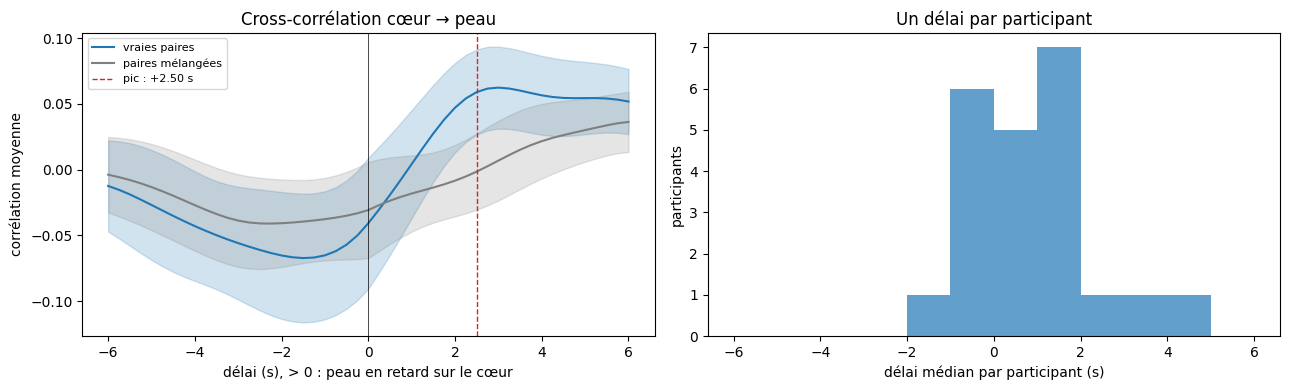

,délai_médian,r_médian,vidéos
participant,,,
P001,-1.00,0.39,34
P017,-0.75,0.34,34
P020,1.50,0.51,35
P086,4.62,0.40,34
P090,-0.38,0.48,10
P097,0.00,0.33,35
P126,0.50,0.47,34
P128,1.75,0.43,35
P129,0.00,0.38,35


In [9]:
rng = np.random.default_rng(1)
xc_rows, curves_true, curves_null = [], [], []
for p, d in videos.groupby("participant_id"):
    idx = d.index.to_numpy()
    partner = np.roll(idx, 1)          # peau de la vidéo voisine : même personne, autre vidéo
    for i, j in zip(idx, partner):
        h, g, g_other = videos.hr.at[i], videos.gsr.at[i], videos.gsr.at[j]
        n = min(len(h), len(g_other))
        lag, r = latence(h, g, FS_GRID, LAG_MAX_S, sign=+1)
        xc_rows.append({"participant": p, "start_marker": videos.start_marker.at[i],
                        "activation": videos.activation.at[i], "délai (s)": lag, "r": r})
        curves_true.append((p, xcorr_curve(h, g)))
        curves_null.append((p, xcorr_curve(h[:n], g_other[:n])))
xc = pd.DataFrame(xc_rows)


def mean_by_participant(curves):
    frame = pd.DataFrame([c for _, c in curves], index=[p for p, _ in curves], columns=LAG_GRID)
    return frame.groupby(level=0).mean()


true_pp, null_pp = mean_by_participant(curves_true), mean_by_participant(curves_null)
diff_pp = true_pp - null_pp
peak_lag = float(diff_pp.mean().idxmax())
rng_b = np.random.default_rng(2)
boot = [float(diff_pp.iloc[rng_b.integers(0, len(diff_pp), len(diff_pp))].mean().idxmax()) for _ in range(2000)]
at_peak = diff_pp[peak_lag]
print(f"Pic de la courbe moyenne (vraies paires − paires mélangées) : {peak_lag:+.2f} s, "
      f"IC 95 % [{np.percentile(boot, 2.5):+.2f} ; {np.percentile(boot, 97.5):+.2f}] s")
print(f"À ce délai, corrélation vraies − mélangées : {at_peak.mean():+.3f} ; "
      f"plus forte que les paires mélangées chez {(at_peak > 0).sum()} / {len(at_peak)} participants "
      f"(Wilcoxon p = {wilcoxon(at_peak).pvalue:.3f})")

xc_pp = xc.groupby("participant").agg(délai_médian=("délai (s)", "median"), r_médian=("r", "median"),
                                      vidéos=("r", "size"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for frame, label, color in [(true_pp, "vraies paires", "tab:blue"), (null_pp, "paires mélangées", "tab:gray")]:
    m, s = frame.mean(), frame.std() / np.sqrt(len(frame))
    axes[0].plot(LAG_GRID, m, color=color, label=label)
    axes[0].fill_between(LAG_GRID, m - 1.96 * s, m + 1.96 * s, color=color, alpha=0.2)
axes[0].axvline(peak_lag, color="tab:red", ls="--", lw=1, label=f"pic : {peak_lag:+.2f} s")
axes[0].axvline(0, color="k", lw=0.5)
axes[0].set(xlabel="délai (s), > 0 : peau en retard sur le cœur", ylabel="corrélation moyenne",
            title="Cross-corrélation cœur → peau")
axes[0].legend(fontsize=8)
axes[1].hist(xc_pp.délai_médian, bins=np.arange(-LAG_MAX_S, LAG_MAX_S + 0.5, 1), color="tab:blue", alpha=0.7)
axes[1].set(xlabel="délai médian par participant (s)", ylabel="participants", title="Un délai par participant")
plt.tight_layout()
plt.show()
display(xc_pp.round(2))

### 5.2 · Régression linéaire et autoencodeur : l'erreur de traduction selon le décalage

Chaque courbe donne l'erreur de traduction cœur → peau sur des participants jamais vus, pour chaque décalage de la peau. Le **minimum** donne le délai. La ligne grise donne l'erreur avec des **paires mélangées** au même délai : si la courbe ne passe pas nettement dessous, la méthode ne trouve pas de vrai lien.

C'est la cellule longue : `len(TAUS)` × `N_FOLDS` autoencodeurs, deux fois (vraies paires, paires mélangées).

τ = -2.0 s fait
τ = -1.5 s fait
τ = -1.0 s fait
τ = -0.5 s fait
τ = +0.0 s fait
τ = +0.5 s fait
τ = +1.0 s fait
τ = +1.5 s fait
τ = +2.0 s fait
τ = +2.5 s fait
τ = +3.0 s fait
τ = +3.5 s fait
τ = +4.0 s fait
τ = +4.5 s fait
τ = +5.0 s fait
τ = +5.5 s fait
τ = +6.0 s fait
Fait en 4.0 min


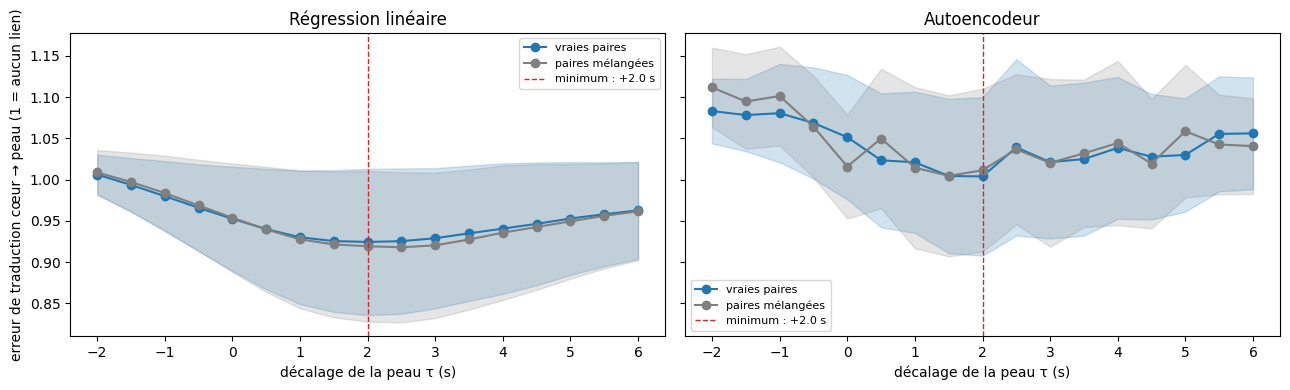

,méthode,délai (s),IC 95 % bas,IC 95 % haut,gain sur paires mélangées,participants où le vrai lien gagne,p (Wilcoxon)
0,Régression linéaire,2.0,1.0,6.0,-0.005,9 / 22,0.371
1,Autoencodeur,2.0,0.5,5.0,0.007,13 / 22,0.588


In [10]:
t0 = time.time()
curves = translation_curves(videos)
partner = np.arange(len(videos))
for _, d in videos.groupby("participant_id"):
    partner[d.index.to_numpy()] = np.roll(d.index.to_numpy(), 1)   # peau de la vidéo voisine, même personne
curves_shuffled = translation_curves(videos, pair_with=partner, verbose=False)
print(f"Fait en {(time.time() - t0) / 60:.1f} min")

pp, pp_shuffled = per_participant(curves), per_participant(curves_shuffled)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
summary_rows = []
for ax, method in zip(axes, ["Régression linéaire", "Autoencodeur"]):
    for frame, label, color in [(pp, "vraies paires", "tab:blue"), (pp_shuffled, "paires mélangées", "tab:gray")]:
        c = frame[frame.méthode == method].pivot(index="participant", columns="tau", values="erreur")
        m, s = c.mean(), c.std() / np.sqrt(len(c))
        ax.plot(TAUS, m, marker="o", color=color, label=label)
        ax.fill_between(TAUS, m - 1.96 * s, m + 1.96 * s, color=color, alpha=0.2)
    tau_hat, lo, hi = bootstrap_tau(pp, method)
    true_w = pp[pp.méthode == method].pivot(index="participant", columns="tau", values="erreur")
    shuf_w = pp_shuffled[pp_shuffled.méthode == method].pivot(index="participant", columns="tau", values="erreur")
    gain = (shuf_w[tau_hat] - true_w[tau_hat]).dropna()
    summary_rows.append({"méthode": method, "délai (s)": tau_hat, "IC 95 % bas": lo, "IC 95 % haut": hi,
                         "gain sur paires mélangées": gain.mean(),
                         "participants où le vrai lien gagne": f"{(gain > 0).sum()} / {len(gain)}",
                         "p (Wilcoxon)": wilcoxon(gain).pvalue if len(gain) >= 5 and np.any(gain != 0) else np.nan})
    ax.axvline(tau_hat, color="tab:red", ls="--", lw=1, label=f"minimum : {tau_hat:+.1f} s")
    ax.set(title=method, xlabel="décalage de la peau τ (s)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("erreur de traduction cœur → peau (1 = aucun lien)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(summary_rows).round(3))

### 5.3 · Les méthodes sont-elles d'accord ?

Le résultat de l'équipe n'est solide que si les méthodes indépendantes trouvent le même délai. Le tableau rassemble les trois estimations ; la corrélation de rang compare, participant par participant, le délai de la cross-corrélation et celui de l'autoencodeur.

In [11]:
agree = pd.DataFrame([{"méthode": "Cross-corrélation (pic moyen − paires mélangées)", "délai (s)": peak_lag,
                       "IC 95 % bas": np.percentile(boot, 2.5), "IC 95 % haut": np.percentile(boot, 97.5)}]
                     + [{k: r[k] for k in ["méthode", "délai (s)", "IC 95 % bas", "IC 95 % haut"]} for r in summary_rows])
display(agree.round(2))

ae_wide = pp[pp.méthode == "Autoencodeur"].pivot(index="participant", columns="tau", values="erreur")
per_person = pd.DataFrame({"cross-corrélation": xc_pp.délai_médian,
                           "autoencodeur": ae_wide.idxmin(axis=1)}).dropna()
rho, p = spearmanr(per_person["cross-corrélation"], per_person["autoencodeur"])
print(f"Délai par participant, cross-corrélation vs autoencodeur : Spearman ρ = {rho:.2f} (p = {p:.3f}, "
      f"{len(per_person)} participants)")

,méthode,délai (s),IC 95 % bas,IC 95 % haut
0,Cross-corrélation (pic moyen − paires mélangées),2.5,2.0,3.0
1,Régression linéaire,2.0,1.0,6.0
2,Autoencodeur,2.0,0.5,5.0


Délai par participant, cross-corrélation vs autoencodeur : Spearman ρ = -0.12 (p = 0.586, 22 participants)


## 6 · Le délai change-t-il avec l'activation ?

Deux façons de répondre, sur les vidéos de chaque participant classées « haute » et « basse » :

- **Cross-corrélation :** pour chaque participant, le délai médian de ses vidéos hautes moins celui de ses vidéos basses ; test de Wilcoxon sur ces différences.
- **Autoencodeur :** la courbe d'erreur de traduction séparément pour les vidéos hautes et basses (même modèle, appris sans les notes) ; on compare leurs minimums.

Attention : chaque participant n'a qu'une dizaine de vidéos par groupe. Un délai par vidéo est bruité ; la comparaison porte sur des médianes par participant.

Cross-corrélation : délai médian haute -0.12 s, basse +0.81 s ; différence moyenne +0.06 s, haute plus tardive chez 12 / 22 participants, p = 0.846


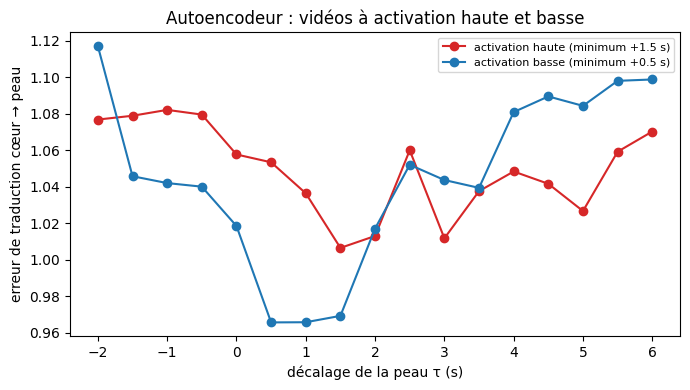

In [12]:
hl = xc[xc.activation.isin(["haute", "basse"])].groupby(["participant", "activation"])["délai (s)"].median().unstack()
hl = hl.dropna()
d = hl["haute"] - hl["basse"]
print(f"Cross-corrélation : délai médian haute {hl['haute'].median():+.2f} s, basse {hl['basse'].median():+.2f} s ; "
      f"différence moyenne {d.mean():+.2f} s, haute plus tardive chez {(d > 0).sum()} / {len(d)} participants, "
      f"p = {wilcoxon(d).pvalue if np.any(d != 0) else float('nan'):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for act, color in [("haute", "tab:red"), ("basse", "tab:blue")]:
    c = curves[(curves.méthode == "Autoencodeur") & (curves.activation == act)]
    c = c.assign(tot=c.erreur * c.n).groupby(["participant", "tau"])[["tot", "n"]].sum()
    wide = (c.tot / c.n).unstack()
    m = wide.mean()
    ax.plot(TAUS, m, marker="o", color=color, label=f"activation {act} (minimum {best_tau(m):+.1f} s)")
ax.set(xlabel="décalage de la peau τ (s)", ylabel="erreur de traduction cœur → peau",
       title="Autoencodeur : vidéos à activation haute et basse")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7 · L'autoencodeur sans la réponse commune, et la prédiction de l'arousal

**Pourquoi.** En 5.2, l'autoencodeur ne faisait pas mieux que les paires mélangées. Explication probable : toutes les vidéos provoquent la même réponse type (début de vidéo, fin de vidéo), et l'autoencodeur apprend surtout cette forme commune, que les paires mélangées ont aussi.

**Ce qu'on fait ici :**

1. **Retirer la réponse commune.** Pour chaque vidéo, on soustrait la réponse moyenne des **autres** vidéos du même participant (cœur et peau, calées sur le début de la vidéo). Il ne reste que ce qui est propre à cette vidéo.
2. **Refaire le test de 5.2 sur ces résidus.** Si l'autoencodeur bat maintenant les paires mélangées, il capte un vrai lien cœur → peau propre à chaque vidéo.
3. **Prédire l'arousal** à partir du code de l'autoencodeur (moyenne de ses codes sur les morceaux de chaque vidéo), avec la même sonde que dans les notebooks précédents, sur des participants jamais vus.
4. **Variante MMD** (idée reprise de l'article PCAE) : un terme de la perte pousse les codes de chaque participant à avoir la même distribution que l'ensemble. Le but : un code moins propre à chaque personne, donc plus utile sur une personne jamais vue.

**Au passage**, la première cellule trace les **réponses moyennes** du cœur et de la peau pour les vidéos à activation haute et basse : c'est la méthode classique en psychophysiologie pour voir un effet de l'arousal.

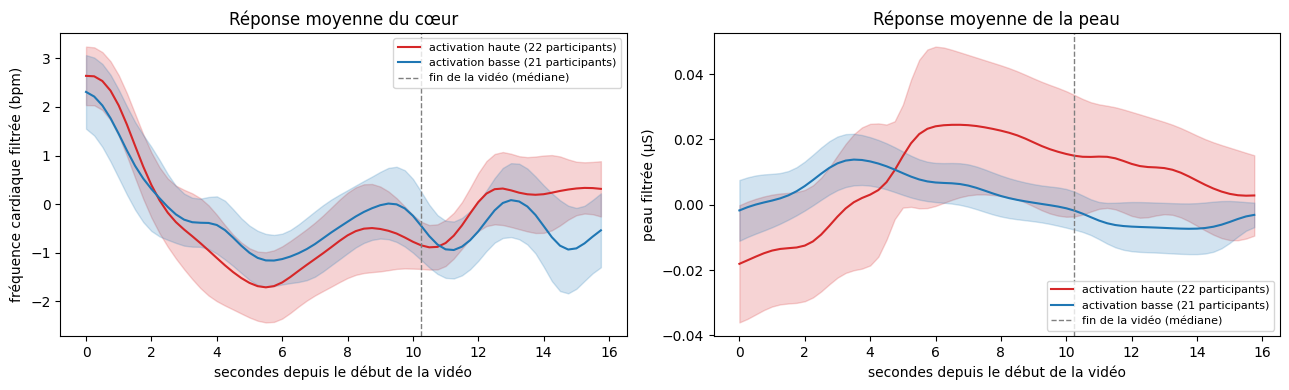

Réponse moyenne (peau, 2–10 s) : haute − basse = +0.0089, plus forte en haute chez 13 / 21 participants, p = 0.082
Réponse moyenne (cœur, 0–6 s) : haute − basse = -0.1222, plus forte en haute chez 9 / 21 participants, p = 0.452


In [13]:
N_COMMON = int(min(videos.hr.map(len).min(), videos.gsr.map(len).min()))
t_axis = np.arange(N_COMMON) / FS_GRID
hr_res, gsr_res, mean_rows = [None] * len(videos), [None] * len(videos), []
for p, d in videos.groupby("participant_id"):
    H = np.vstack([h[:N_COMMON] for h in d.hr])
    G = np.vstack([g[:N_COMMON] for g in d.gsr])
    k = len(d)
    for j, idx in enumerate(d.index):
        hr_res[idx] = H[j] - (H.sum(0) - H[j]) / (k - 1)      # moins la moyenne des AUTRES vidéos
        gsr_res[idx] = G[j] - (G.sum(0) - G[j]) / (k - 1)
    for act in ["haute", "basse"]:
        m = (d.activation == act).to_numpy()
        if m.sum() >= 3:
            mean_rows.append({"participant": p, "activation": act, "hr": H[m].mean(0), "gsr": G[m].mean(0)})
residuals = videos.copy()
residuals["hr"], residuals["gsr"] = hr_res, gsr_res
means = pd.DataFrame(mean_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, sig, unit in [(axes[0], "hr", "fréquence cardiaque filtrée (bpm)"), (axes[1], "gsr", "peau filtrée (µS)")]:
    for act, color in [("haute", "tab:red"), ("basse", "tab:blue")]:
        M = np.vstack(means.loc[means.activation == act, sig])
        m, se = M.mean(0), M.std(0) / np.sqrt(len(M))
        ax.plot(t_axis, m, color=color, label=f"activation {act} ({len(M)} participants)")
        ax.fill_between(t_axis, m - 1.96 * se, m + 1.96 * se, color=color, alpha=0.2)
    ax.axvline(videos.video_s.median(), color="gray", ls="--", lw=1, label="fin de la vidéo (médiane)")
    ax.set(xlabel="secondes depuis le début de la vidéo", ylabel=unit)
    ax.legend(fontsize=8)
axes[0].set_title("Réponse moyenne du cœur")
axes[1].set_title("Réponse moyenne de la peau")
plt.tight_layout()
plt.show()

wide = {act: means[means.activation == act].set_index("participant") for act in ["haute", "basse"]}
both = wide["haute"].index.intersection(wide["basse"].index)
for sig, (a, b), name in [("gsr", (2, 10), "peau, 2–10 s"), ("hr", (0, 6), "cœur, 0–6 s")]:
    sel = (t_axis >= a) & (t_axis < b)
    d = np.array([wide["haute"].at[p, sig][sel].mean() - wide["basse"].at[p, sig][sel].mean() for p in both])
    print(f"Réponse moyenne ({name}) : haute − basse = {d.mean():+.4f}, plus forte en haute chez {(d > 0).sum()} / {len(d)} "
          f"participants, p = {wilcoxon(d).pvalue:.3f}")

### 7.1 · L'autoencodeur sur les résidus contre les paires mélangées

Même test qu'en 5.2, sur les signaux sans la réponse commune. Le tableau compare directement les signaux bruts (5.2) et les résidus.

τ = -2.0 s fait
τ = -1.5 s fait
τ = -1.0 s fait
τ = -0.5 s fait
τ = +0.0 s fait
τ = +0.5 s fait
τ = +1.0 s fait
τ = +1.5 s fait
τ = +2.0 s fait
τ = +2.5 s fait
τ = +3.0 s fait
τ = +3.5 s fait
τ = +4.0 s fait
τ = +4.5 s fait
τ = +5.0 s fait
τ = +5.5 s fait
τ = +6.0 s fait
Fait en 3.0 min


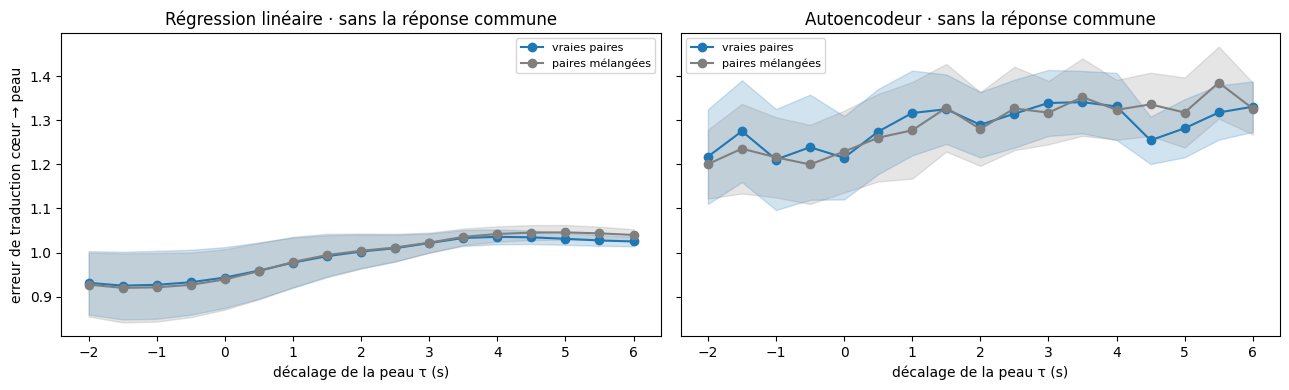

,signaux,méthode,délai (s),IC 95 % bas,IC 95 % haut,gain sur paires mélangées,participants où le vrai lien gagne,p (Wilcoxon)
0,bruts (5.2),Régression linéaire,2.0,1.0,6.0,-0.005,9 / 22,0.371
1,bruts (5.2),Autoencodeur,2.0,0.5,5.0,0.007,13 / 22,0.588
2,sans réponse commune,Régression linéaire,-1.5,-2.0,-0.5,-0.005,12 / 22,0.566
3,sans réponse commune,Autoencodeur,-1.0,-2.0,4.5,0.005,13 / 22,0.824


In [14]:
t0 = time.time()
curves_res = translation_curves(residuals)
curves_res_shuffled = translation_curves(residuals, pair_with=partner, verbose=False)
print(f"Fait en {(time.time() - t0) / 60:.1f} min")
pp_res, pp_res_shuffled = per_participant(curves_res), per_participant(curves_res_shuffled)


def versus_shuffled(pp_true, pp_shuf, method, label):
    tau_hat, lo, hi = bootstrap_tau(pp_true, method)
    t_w = pp_true[pp_true.méthode == method].pivot(index="participant", columns="tau", values="erreur")
    s_w = pp_shuf[pp_shuf.méthode == method].pivot(index="participant", columns="tau", values="erreur")
    gain = (s_w[tau_hat] - t_w[tau_hat]).dropna()
    return {"signaux": label, "méthode": method, "délai (s)": tau_hat, "IC 95 % bas": lo, "IC 95 % haut": hi,
            "gain sur paires mélangées": gain.mean(), "participants où le vrai lien gagne": f"{(gain > 0).sum()} / {len(gain)}",
            "p (Wilcoxon)": wilcoxon(gain).pvalue if len(gain) >= 5 and np.any(gain != 0) else np.nan}


fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, method in zip(axes, ["Régression linéaire", "Autoencodeur"]):
    for frame, label, color in [(pp_res, "vraies paires", "tab:blue"), (pp_res_shuffled, "paires mélangées", "tab:gray")]:
        c = frame[frame.méthode == method].pivot(index="participant", columns="tau", values="erreur")
        m, s = c.mean(), c.std() / np.sqrt(len(c))
        ax.plot(TAUS, m, marker="o", color=color, label=label)
        ax.fill_between(TAUS, m - 1.96 * s, m + 1.96 * s, color=color, alpha=0.2)
    ax.set(title=f"{method} · sans la réponse commune", xlabel="décalage de la peau τ (s)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("erreur de traduction cœur → peau")
plt.tight_layout()
plt.show()
display(pd.DataFrame([versus_shuffled(a, b, m, lab) for lab, a, b in [("bruts (5.2)", pp, pp_shuffled),
                                                                        ("sans réponse commune", pp_res, pp_res_shuffled)]
                      for m in ["Régression linéaire", "Autoencodeur"]]).round(3))

### 7.2 · Le code de l'autoencodeur prédit-il l'arousal ?

L'autoencodeur est appris **sans les notes**, au décalage trouvé par la cross-corrélation (5.1). Ici, les morceaux ne sont pas standardisés un par un mais par participant : l'**amplitude** des réponses est gardée, car c'est elle qui porte le plus l'arousal (une grande réaction de la peau = une forte activation). Pour chaque vidéo, son résumé est la moyenne **et l'écart-type** de ses codes sur les morceaux de la vidéo (la moyenne seule effacerait l'ampleur des réactions). Puis la même sonde que d'habitude (régression logistique, arousal au-dessus de la médiane du participant), notée sur des participants jamais vus.

| Version | Ce que reçoit la sonde |
| --- | --- |
| Signaux bruts · direct | les courbes du cœur et de la peau elles-mêmes, moyennées par seconde, et leur écart-type (pas d'autoencodeur) |
| Autoencodeur · bruts | le code appris sur les signaux bruts |
| Autoencodeur · résidus | le code appris sans la réponse commune |
| Autoencodeur · résidus + MMD | pareil, avec le terme MMD entre participants (`MMD_WEIGHT`) |

In [15]:
TAU_PRED = float(TAUS[np.argmin(np.abs(TAUS - peak_lag))])
MMD_WEIGHT, MMD_SAMPLE = 1.0, 64
print(f"Décalage utilisé : {TAU_PRED:+.1f} s (pic de la cross-corrélation)")


def segments_by_video(table, tau):
    x, y, _, _ = segments(table, tau, norm="participant")
    lead, tail, shift = int(round(-TAUS.min() * FS_GRID)), int(round(TAUS.max() * FS_GRID)), int(round(tau * FS_GRID))
    vid = [i for i, row in enumerate(table.itertuples())
           for s in range(lead, min(len(row.hr), len(row.gsr)) - SEG_N - tail + 1, STEP_N)]
    return x, y, np.array(vid)


def mmd(a, b):
    # Écart entre deux nuages de points (noyau gaussien) : 0 si les distributions sont identiques.
    def k(u, v):
        return torch.exp(-torch.cdist(u, v) ** 2 / (2 * LATENT))
    return k(a, a).mean() + k(b, b).mean() - 2 * k(a, b).mean()


def fit_ae(x, y, people, mmd_weight=0.0, seed=0):
    torch.manual_seed(seed)
    gen = np.random.default_rng(seed)
    model = HeartSkinAE(x.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    xt, yt = torch.as_tensor(x, dtype=torch.float32), torch.as_tensor(y, dtype=torch.float32)
    groups_idx = [np.flatnonzero(people == p) for p in np.unique(people)]
    for _ in range(EPOCHS):
        opt.zero_grad()
        loss = model.loss(xt, yt)
        if mmd_weight > 0:
            z = (model.enc_hr(xt) + model.enc_gsr(yt)) / 2
            pool = torch.as_tensor(gen.choice(len(x), MMD_SAMPLE * 4, replace=False))
            terms = [mmd(z[torch.as_tensor(gen.choice(ix, min(MMD_SAMPLE, len(ix)), replace=False))], z[pool])
                     for ix in groups_idx]
            loss = loss + mmd_weight * torch.stack(terms).mean()
        loss.backward()
        opt.step()
    return model.eval()


@torch.no_grad()
def video_codes(model, x, y, vid, n_videos):
    z = torch.cat([model.enc_hr(torch.as_tensor(x, dtype=torch.float32)),
                   model.enc_gsr(torch.as_tensor(y, dtype=torch.float32))], dim=1).numpy()
    # Résumé d'une vidéo = moyenne ET écart-type de ses codes : la moyenne seule efface l'ampleur des réactions.
    out = np.full((n_videos, 2 * z.shape[1]), np.nan)
    for v in np.unique(vid):
        out[v] = np.r_[z[vid == v].mean(axis=0), z[vid == v].std(axis=0)]
    return out


def per_second(table):
    n = int(N_COMMON // FS_GRID) * int(FS_GRID)
    hr = np.vstack([h[:n] for h in table.hr])
    gsr = np.vstack([g[:n] for g in table.gsr])
    return np.column_stack([hr.reshape(len(table), -1, int(FS_GRID)).mean(2), gsr.reshape(len(table), -1, int(FS_GRID)).mean(2),
                            hr.std(axis=1), gsr.std(axis=1)])   # + l'ampleur des variations


median_rating = videos.groupby("participant_id").rating_arousal.transform("median")
target = videos.rating_arousal.gt(median_rating).astype(float).where(videos.rating_arousal.notna()).to_numpy()
groups_v = videos.participant_id.to_numpy()


def standardize_by_participant(f):
    f = pd.DataFrame(f).groupby(groups_v).transform(lambda c: (c - c.mean()) / c.std(ddof=0))
    return f.replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy()


people = np.unique(groups_v)
splits = list(GroupKFold(n_splits=min(N_FOLDS, len(people))).split(people, groups=people))
# Les mesures directes standardisées par participant n'ont pas besoin de version « résidus » :
# retirer la moyenne des autres vidéos du participant ne change rien après cette standardisation.
direct = {"Signaux bruts · direct": standardize_by_participant(per_second(videos))}
seg = {"bruts": segments_by_video(videos, TAU_PRED), "résidus": segments_by_video(residuals, TAU_PRED)}
seg_people = {k: groups_v[v[2]] for k, v in seg.items()}

pred_rows = []
t0 = time.time()
for f_i, (tr_p, te_p) in enumerate(splits):
    tr_v, te_v = np.isin(groups_v, people[tr_p]), np.isin(groups_v, people[te_p])
    features = dict(direct)
    for name, kind, w in [("Autoencodeur · bruts", "bruts", 0.0), ("Autoencodeur · résidus", "résidus", 0.0),
                          ("Autoencodeur · résidus + MMD", "résidus", MMD_WEIGHT)]:
        x, y, vid = seg[kind]
        train_seg = np.isin(seg_people[kind], people[tr_p])
        model = fit_ae(x[train_seg], y[train_seg], seg_people[kind][train_seg], mmd_weight=w)
        features[name] = standardize_by_participant(video_codes(model, x, y, vid, len(videos)))
    for name, f in features.items():
        tr = np.flatnonzero(tr_v & np.isfinite(target))
        probe = LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000).fit(f[tr], target[tr])
        for p in people[te_p]:
            te = np.flatnonzero((groups_v == p) & np.isfinite(target))
            if len(te) < 5 or len(set(target[te])) < 2:
                continue
            prob = probe.predict_proba(f[te])[:, 1]
            pred_rows.append({"participant": p, "version": name, "AUC": roc_auc_score(target[te], prob),
                              "balanced accuracy": balanced_accuracy_score(target[te], prob > 0.5)})
    print(f"groupe {f_i + 1}/{len(splits)} fait ({(time.time() - t0) / 60:.1f} min)")

pred = pd.DataFrame(pred_rows)
ORDER_PRED = ["Signaux bruts · direct", "Autoencodeur · bruts", "Autoencodeur · résidus",
              "Autoencodeur · résidus + MMD"]
display(pred.groupby("version")[["AUC", "balanced accuracy"]].agg(["mean", "std"]).reindex(ORDER_PRED).round(3))
pairs = [("Autoencodeur · bruts", "Signaux bruts · direct"), ("Autoencodeur · résidus", "Autoencodeur · bruts"),
         ("Autoencodeur · résidus + MMD", "Autoencodeur · résidus"), ("Autoencodeur · résidus + MMD", "Signaux bruts · direct")]
for metric in ["AUC", "balanced accuracy"]:
    w = pred.pivot(index="participant", columns="version", values=metric)
    rows_cmp = []
    for a, b in pairs:
        d = (w[a] - w[b]).dropna().to_numpy()
        rng_b = np.random.default_rng(0)
        boot = [rng_b.choice(d, size=len(d), replace=True).mean() for _ in range(5000)]
        rows_cmp.append({"A": a, "B": b, "victoires de A": f"{int((d > 0).sum())} / {len(d)}", "différence moyenne": d.mean(),
                         "IC 95 % bas": np.percentile(boot, 2.5), "IC 95 % haut": np.percentile(boot, 97.5),
                         "p (Wilcoxon)": wilcoxon(d).pvalue if np.any(d != 0) else np.nan})
    print(f"\nMesure : {metric}")
    display(pd.DataFrame(rows_cmp).round(3))

Décalage utilisé : +2.5 s (pic de la cross-corrélation)
groupe 1/5 fait (0.2 min)
groupe 2/5 fait (0.4 min)
groupe 3/5 fait (0.6 min)
groupe 4/5 fait (0.8 min)
groupe 5/5 fait (1.1 min)


AUC        balanced accuracy       
                               mean    std              mean    std
version                                                            
Signaux bruts · direct        0.523  0.108             0.511  0.084
Autoencodeur · bruts          0.537  0.111             0.515  0.107
Autoencodeur · résidus        0.496  0.111             0.503  0.094
Autoencodeur · résidus + MMD  0.489  0.094             0.511  0.094


Mesure : AUC


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,Autoencodeur · bruts,Signaux bruts · direct,14 / 22,0.015,-0.032,0.060,0.503
1,Autoencodeur · résidus,Autoencodeur · bruts,8 / 22,-0.041,-0.101,0.018,0.156
2,Autoencodeur · résidus + MMD,Autoencodeur · résidus,8 / 22,-0.007,-0.026,0.009,0.958
3,Autoencodeur · résidus + MMD,Signaux bruts · direct,7 / 22,-0.033,-0.080,0.014,0.149



Mesure : balanced accuracy


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,Autoencodeur · bruts,Signaux bruts · direct,12 / 22,0.004,-0.049,0.053,0.602
1,Autoencodeur · résidus,Autoencodeur · bruts,9 / 22,-0.013,-0.071,0.050,0.498
2,Autoencodeur · résidus + MMD,Autoencodeur · résidus,9 / 22,0.008,-0.012,0.030,0.379
3,Autoencodeur · résidus + MMD,Signaux bruts · direct,12 / 22,-0.000,-0.048,0.044,0.627


## 8 · Comment lire les résultats

**Les questions, dans l'ordre :**

1. **Le contrôle (4.1) retrouve-t-il 3 s ?** Sinon, ne rien conclure de la suite.
2. **Y a-t-il un vrai lien cœur → peau ?** La courbe des vraies paires doit passer nettement au-dessus (cross-corrélation) ou en dessous (erreur de traduction) des paires mélangées, avec un intervalle qui exclut 0. Sinon, il n'y a pas de délai à mesurer, et c'est un résultat.
3. **Quel délai ?** Les trois estimations de 5.3 et leurs intervalles. Si elles se recouvrent, le délai est solide.
4. **Change-t-il avec l'activation ?** Section 6, et les réponses moyennes au début de la section 7.
5. **Sans la réponse commune (7.1), l'autoencodeur bat-il enfin les paires mélangées ?** Si oui, il capte un lien cœur → peau propre à chaque vidéo.
6. **Le code de l'autoencodeur prédit-il l'arousal (7.2) ?** À comparer à « Signaux bruts · direct » (même information, sans autoencodeur) et, pour l'ordre de grandeur, aux ~0,56–0,59 d'AUC des notebooks précédents (essais et participants différents, donc pas une comparaison directe).

**Ce que ça apporte à l'équipe :** le délai retrouvé peut servir à l'étape 4 pour « regarder au bon moment » (décaler la fenêtre de la peau) ou comme nouvelle information pour prédire l'arousal.

**Limites :**

- Le cœur et la peau réagissent tous les deux aux événements de la vidéo : le délai mesuré est la différence entre leurs temps de réaction, pas forcément une influence directe du cœur sur la peau.
- Le filtre 0,02–0,5 Hz et `sign=+1` sont des choix : les changer peut déplacer le délai. Les garder identiques pour toutes les comparaisons.
- `PREPROCESSED` contre `CURATED` : Hugo travaille sur `CURATED`. Refaire l'analyse avec `VERSION = "CURATED"` permet de vérifier que le prétraitement ne change rien.